In [99]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [38]:
air_bnb = pd.read_csv('AB_NYC_2019.csv')

In [3]:
air_bnb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [4]:
air_bnb.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [6]:
air_bnb.dtypes

id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object

In [8]:
air_bnb.shape

(48895, 16)

In [10]:
air_bnb.duplicated().sum()

0

In [39]:
air_bnb.drop(['id','name','host_name','last_review'],axis = 1, inplace = True)

In [40]:
air_bnb.head()

,host_id,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,2787,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,2845,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,4632,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,1,365
3,4869,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,7192,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


In [14]:
air_bnb.isna().sum()

host_id                               0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [41]:
air_bnb.loc[air_bnb['reviews_per_month'].isna(),'number_of_reviews'].value_counts()

number_of_reviews
0    10052
Name: count, dtype: int64

In [42]:
air_bnb['reviews_per_month'].fillna(0, inplace = True)

In [43]:
air_bnb.reviews_per_month.isna().sum()

0

In [44]:
air_bnb.head()

,host_id,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,2787,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,2845,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,4632,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,4869,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,7192,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


In [13]:
air_bnb.isna().sum()

host_id                           0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

In [39]:
air_bnb.neighbourhood_group.unique()

array(['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx'],
      dtype=object)

In [40]:
air_bnb.room_type.unique()

array(['Private room', 'Entire home/apt', 'Shared room'], dtype=object)

In [7]:
air_bnb.host_id.value_counts().head(10)

host_id
219517861    327
107434423    232
30283594     121
137358866    103
16098958      96
12243051      96
61391963      91
22541573      87
200380610     65
7503643       52
Name: count, dtype: int64

In [56]:
top = air_bnb.host_id.value_counts().head(10)

In [51]:
air_bnb.calculated_host_listings_count.max()

327

In [141]:
sns.set(rc={'figure.figsize':(10,9)})
sns.set_style('white')

Text(0.5, 0, 'Host ID')

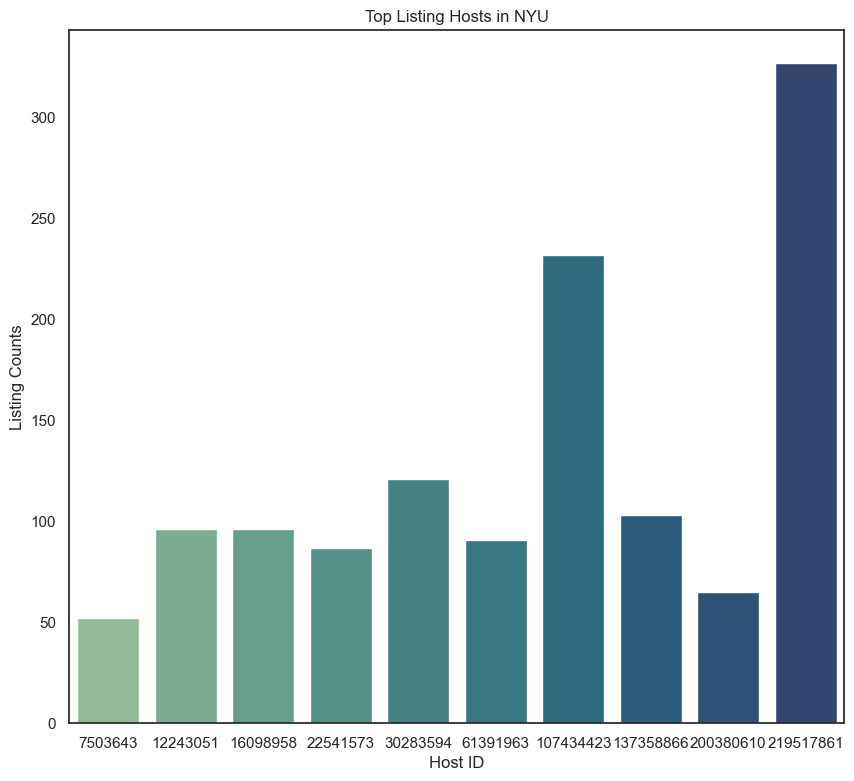

In [139]:
viz_1=sns.barplot(x=top.index, y=top.values, data=air_bnb,
                 palette='crest')
viz_1.set_title('Top Listing Hosts in NYU')
viz_1.set_ylabel('Listing Counts')
viz_1.set_xlabel('Host ID')

In [144]:
air_bnb.neighbourhood_group.value_counts()

neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64

In [15]:
neighbourhood_grp = air_bnb[['neighbourhood_group','price']]

In [16]:
neighbourhood_grp

,neighbourhood_group,price
0,Brooklyn,149
1,Manhattan,225
2,Manhattan,150
3,Brooklyn,89
4,Manhattan,80
...,...,...
48890,Brooklyn,70
48891,Brooklyn,40
48892,Manhattan,115
48893,Manhattan,55


In [26]:
neigh = neighbourhood_grp.groupby('neighbourhood_group').describe()

In [27]:
neigh.columns

MultiIndex([('price', 'count'),
            ('price',  'mean'),
            ('price',   'std'),
            ('price',   'min'),
            ('price',   '25%'),
            ('price',   '50%'),
            ('price',   '75%'),
            ('price',   'max')],
           )

In [28]:
neigh.drop(columns=('price','count'), inplace = True)
neigh.drop(columns=('price','mean'), inplace = True)
neigh.drop(columns=('price','std'), inplace = True)

In [30]:
neigh.T

neighbourhood_group   Bronx  Brooklyn  Manhattan   Queens  Staten Island
price min               0.0       0.0        0.0     10.0           13.0
      25%              45.0      60.0       95.0     50.0           50.0
      50%              65.0      90.0      150.0     75.0           75.0
      75%              99.0     150.0      220.0    110.0          110.0
      max            2500.0   10000.0    10000.0  10000.0         5000.0

In [83]:
neighbourhood_price = air_bnb.loc[air_bnb.price < 500, ['neighbourhood_group','price']]

In [121]:
sns.set(rc={'figure.figsize':(10,9)})
sns.set_style('white')

Text(0.5, 1.0, 'Price Distribution of Neighbourhood Groups')

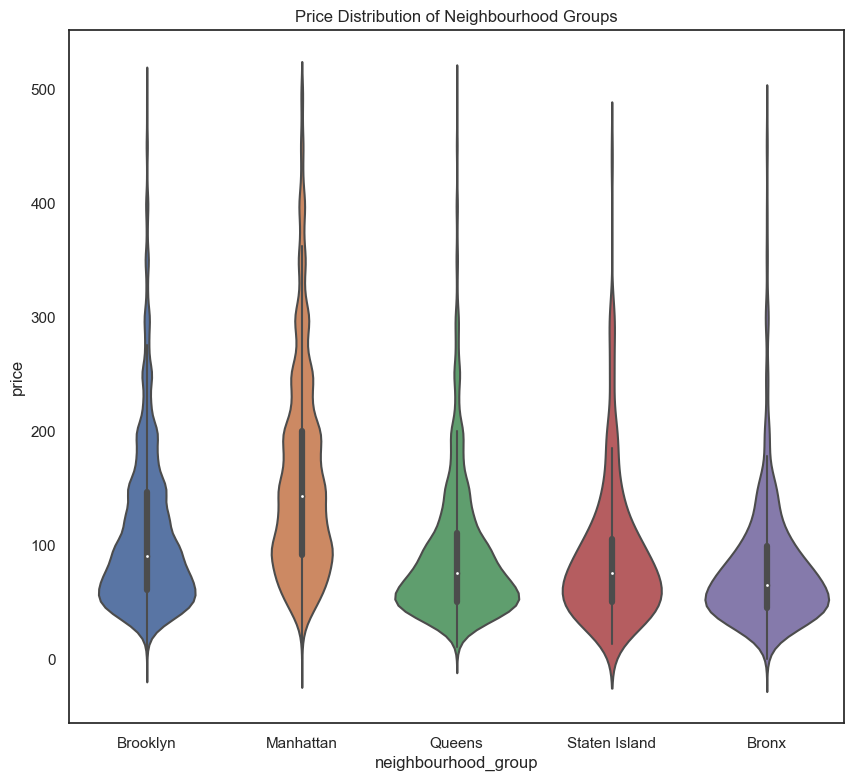

In [122]:
viz_2 = sns.violinplot(neighbourhood_price, x = 'neighbourhood_group', y = 'price')
viz_2.set_title('Price Distribution of Neighbourhood Groups')

In [125]:
air_bnb.neighbourhood.value_counts().head(10)

neighbourhood
Williamsburg          3920
Bedford-Stuyvesant    3714
Harlem                2658
Bushwick              2465
Upper West Side       1971
Hell's Kitchen        1958
East Village          1853
Upper East Side       1798
Crown Heights         1564
Midtown               1545
Name: count, dtype: int64

In [136]:
sub1 = air_bnb.loc[air_bnb.neighbourhood.isin(['Williamsburg','Bedford-Stuyvesant','Harlem','Bushwick','Upper West Side','Hell\'s Kitchen','East Village','Upper East Side','Crown Heights','Midtown'])]

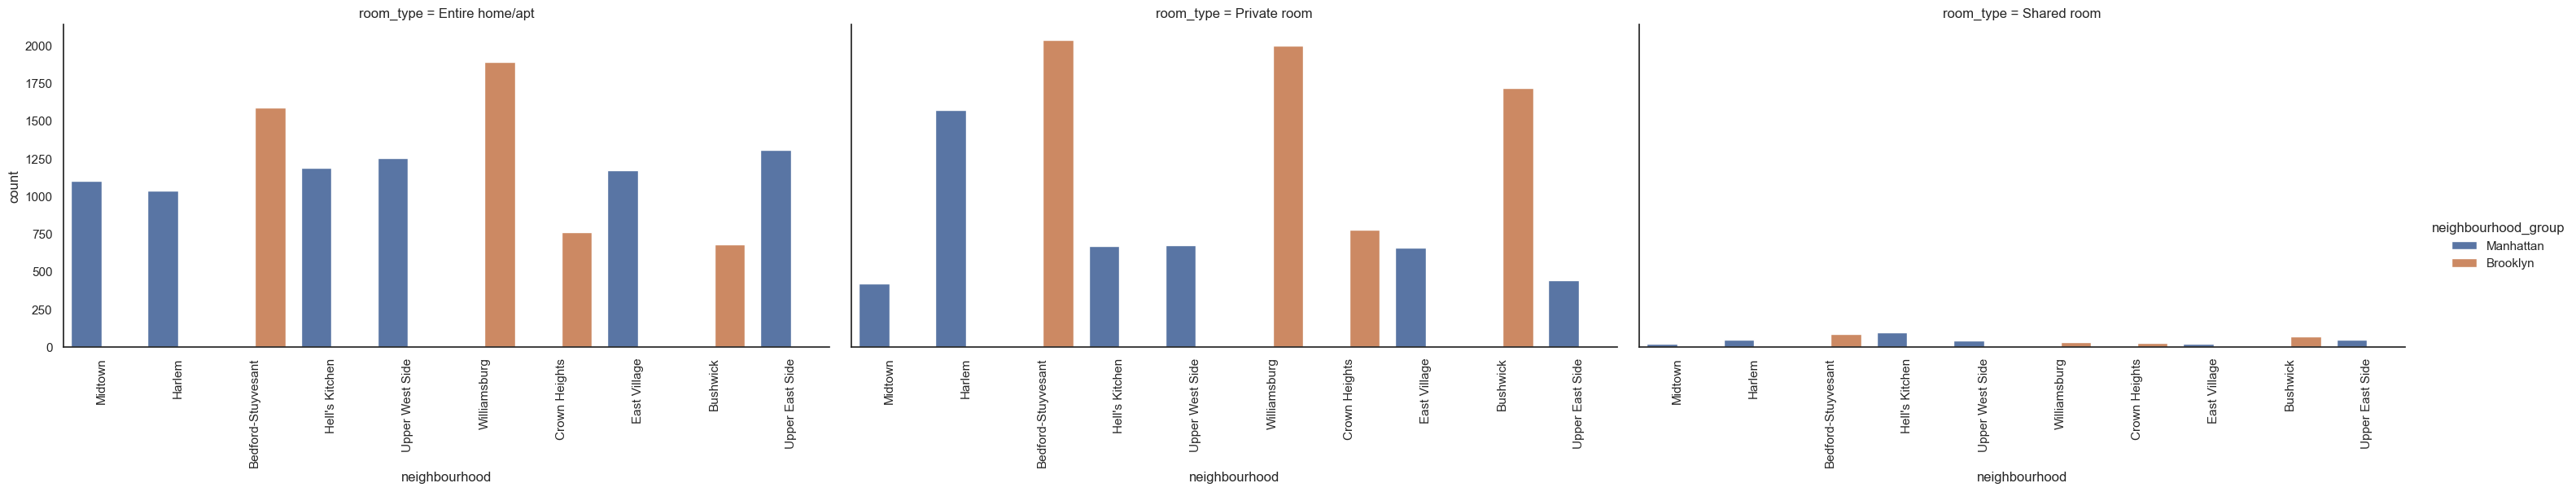

In [150]:
viz_3 = sns.catplot(sub1, x = 'neighbourhood',kind = 'count', hue = 'neighbourhood_group',col = 'room_type' ,aspect = 2, col_wrap = 3)
viz_3.set_xticklabels(rotation = 90)

In [152]:
air_bnb.to_pickle('air_bnb1.pkl')

In [202]:
sns.set_style('darkgrid')

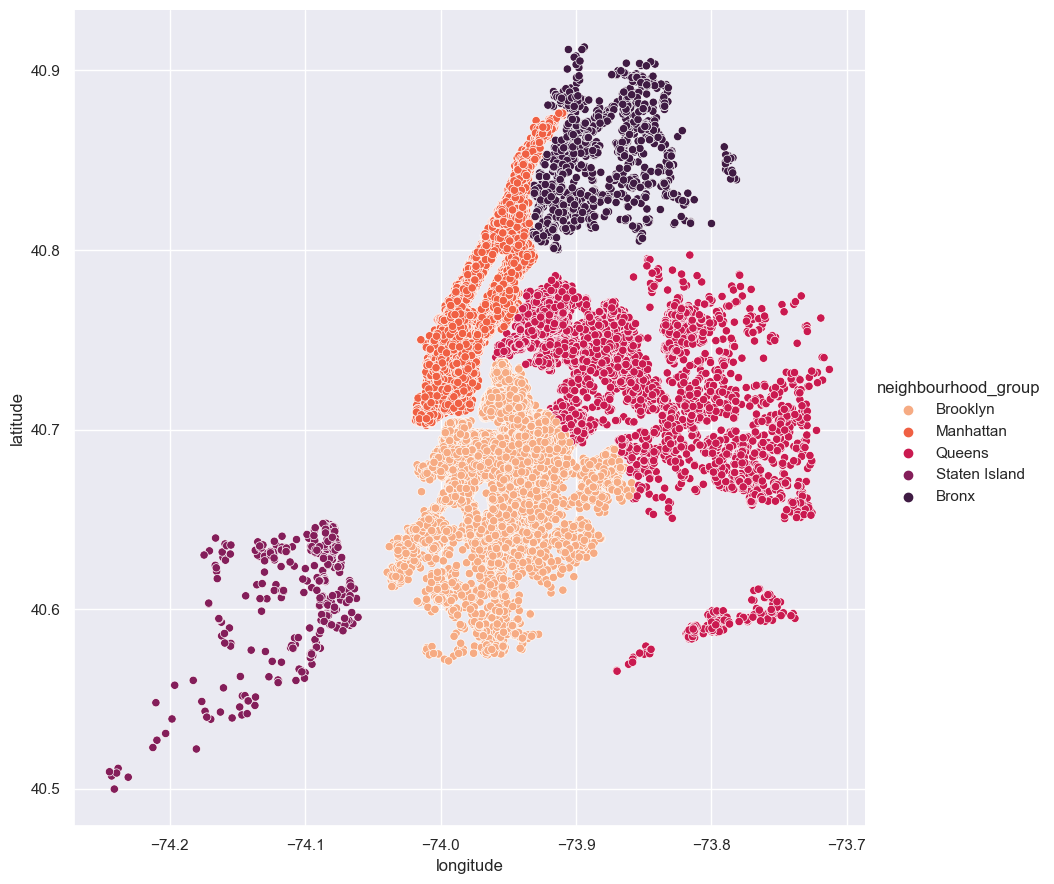

In [210]:
sns.relplot(air_bnb, x = 'longitude', y = 'latitude', hue = 'neighbourhood_group', 
            palette = 'rocket_r',height = 9)

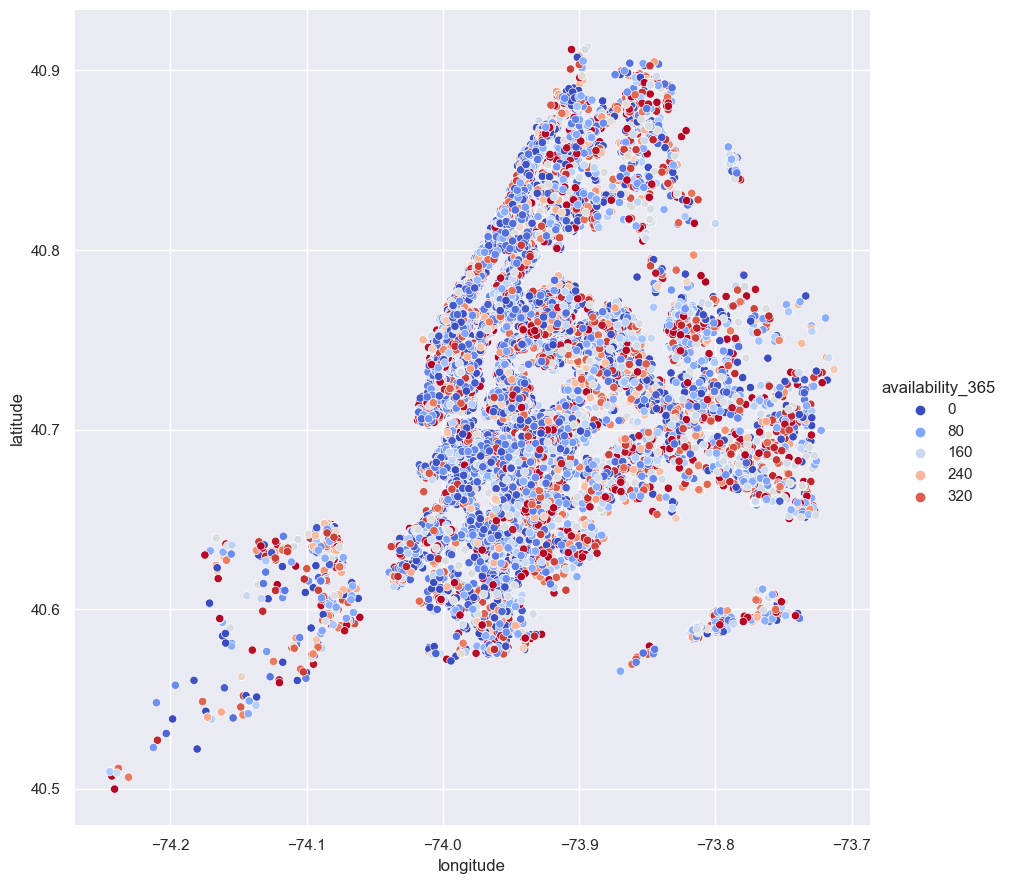

In [209]:
sns.relplot(air_bnb, x = 'longitude', y = 'latitude', hue = 'availability_365', 
            palette = 'coolwarm',height = 9)

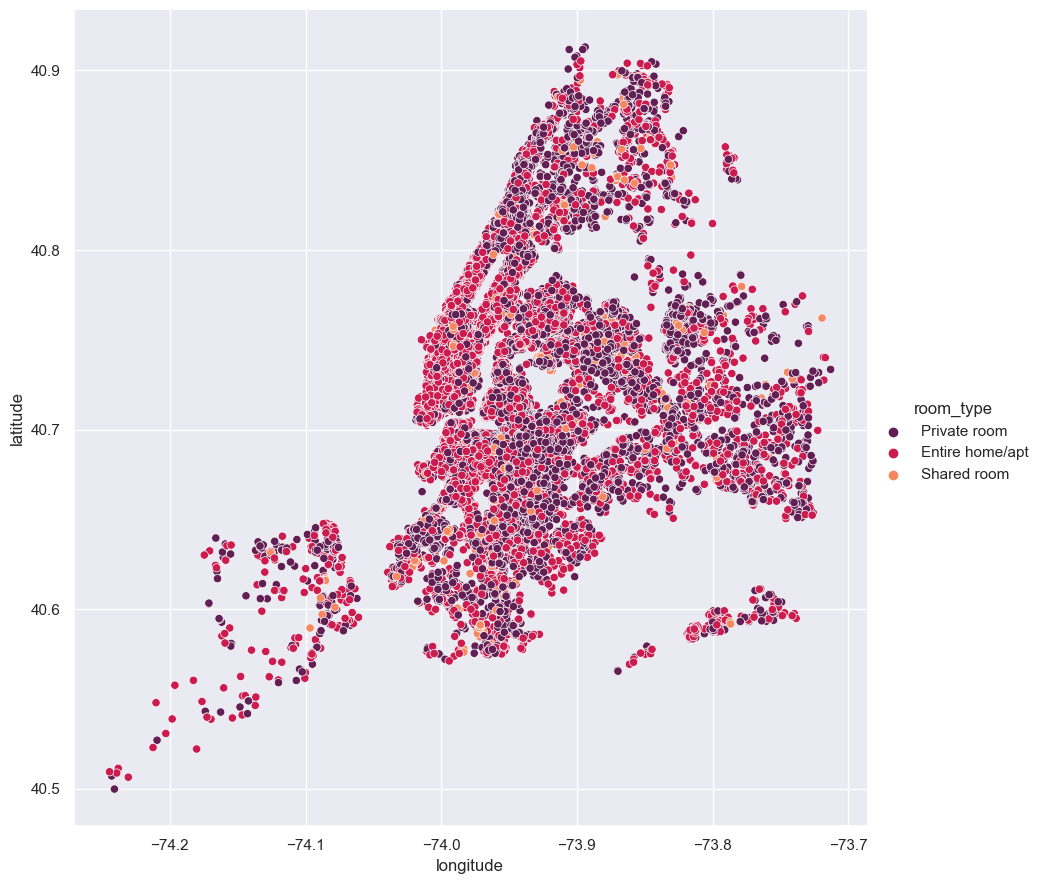

In [213]:
sns.relplot(air_bnb, x = 'longitude', y = 'latitude', hue = 'room_type', 
            palette = 'rocket',height = 9)